## 1. Import the libraries

These are the libraries used in the lab for data handling, visualisation and preprocessing.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

## 2. Load the dataset



In [2]:
df = pd.read_csv("../data/ai4i2020.csv")

print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])
df.head()

Number of rows: 10000
Number of columns: 14


,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


## 3. Dataset metadata

The dataset contains identifiers, product type, machine measurements and failure labels. The target for this project is `Machine failure`.

In [3]:
metadata = pd.DataFrame({
    "Column": [
        "UDI", "Product ID", "Type", "Air temperature [K]",
        "Process temperature [K]", "Rotational speed [rpm]",
        "Torque [Nm]", "Tool wear [min]", "Machine failure",
        "TWF", "HDF", "PWF", "OSF", "RNF"
    ],
    "Description": [
        "Unique row identifier",
        "Product identifier",
        "Product quality type: L, M or H",
        "Air temperature in Kelvin",
        "Process temperature in Kelvin",
        "Rotation speed in revolutions per minute",
        "Torque in Newton-metres",
        "Tool wear in minutes",
        "Target: 0 means no failure and 1 means failure",
        "Tool Wear Failure indicator",
        "Heat Dissipation Failure indicator",
        "Power Failure indicator",
        "Overstrain Failure indicator",
        "Random Failure indicator"
    ],
    "Role": [
        "Identifier - not used as a model input",
        "Identifier - not used as a model input",
        "Input feature",
        "Input feature",
        "Input feature",
        "Input feature",
        "Input feature",
        "Input feature",
        "Target variable",
        "Failure subtype - excluded from inputs",
        "Failure subtype - excluded from inputs",
        "Failure subtype - excluded from inputs",
        "Failure subtype - excluded from inputs",
        "Failure subtype - excluded from inputs"
    ]
})

metadata

,Column,Description,Role
0,UDI,Unique row identifier,Identifier - not used as a model input
1,Product ID,Product identifier,Identifier - not used as a model input
2,Type,"Product quality type: L, M or H",Input feature
3,Air temperature [K],Air temperature in Kelvin,Input feature
4,Process temperature [K],Process temperature in Kelvin,Input feature
5,Rotational speed [rpm],Rotation speed in revolutions per minute,Input feature
6,Torque [Nm],Torque in Newton-metres,Input feature
7,Tool wear [min],Tool wear in minutes,Input feature
8,Machine failure,Target: 0 means no failure and 1 means failure,Target variable
9,TWF,Tool Wear Failure indicator,Failure subtype - excluded from inputs


## 4. Basic inspection

In [4]:
print("Data types and non-missing values:")
df.info()

print("\nsummary:")
df.describe()

Data types and non-missing values:
<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   UDI                      10000 non-null  int64  
 1   Product ID               10000 non-null  str    
 2   Type                     10000 non-null  str    
 3   Air temperature [K]      10000 non-null  float64
 4   Process temperature [K]  10000 non-null  float64
 5   Rotational speed [rpm]   10000 non-null  int64  
 6   Torque [Nm]              10000 non-null  float64
 7   Tool wear [min]          10000 non-null  int64  
 8   Machine failure          10000 non-null  int64  
 9   TWF                      10000 non-null  int64  
 10  HDF                      10000 non-null  int64  
 11  PWF                      10000 non-null  int64  
 12  OSF                      10000 non-null  int64  
 13  RNF                      10000 non-null  int64  
dtyp

,UDI,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
count,10000.00000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.00000
mean,5000.50000,300.004930,310.005560,1538.776100,39.986910,107.951000,0.033900,0.004600,0.011500,0.009500,0.009800,0.00190
std,2886.89568,2.000259,1.483734,179.284096,9.968934,63.654147,0.180981,0.067671,0.106625,0.097009,0.098514,0.04355
min,1.00000,295.300000,305.700000,1168.000000,3.800000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
25%,2500.75000,298.300000,308.800000,1423.000000,33.200000,53.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
50%,5000.50000,300.100000,310.100000,1503.000000,40.100000,108.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
75%,7500.25000,301.500000,311.100000,1612.000000,46.800000,162.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
max,10000.00000,304.500000,313.800000,2886.000000,76.600000,253.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.00000


## 5. Check missing values and duplicate rows

In [29]:
print("Missing values:")
print(df.isnull().sum())

print("Number of duplicate rows:", df.duplicated().sum())

Missing values:
UDI                        0
Product ID                 0
Type                       0
Air temperature [K]        0
Process temperature [K]    0
Rotational speed [rpm]     0
Torque [Nm]                0
Tool wear [min]            0
Machine failure            0
TWF                        0
HDF                        0
PWF                        0
OSF                        0
RNF                        0
dtype: int64
Number of duplicate rows: 0


## 6. Check the target variable

`Machine failure` is the main target variable. Since it has two classes (0 and 1), this is a **binary classification** problem.

Target values:
Machine failure
0    9661
1     339
Name: count, dtype: int64


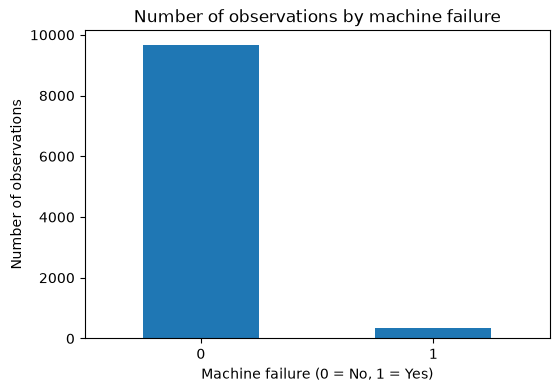

In [9]:
print("Target values:")
print(df["Machine failure"].value_counts())

plt.figure(figsize=(6, 4))
df["Machine failure"].value_counts().plot(kind="bar")
plt.title("Number of observations by machine failure")
plt.xlabel("Machine failure (0 = No, 1 = Yes)")
plt.ylabel("Number of observations")
plt.xticks(rotation=0)
plt.show()

## 7. Explore the numerical features

The five measurements below are numerical inputs. Histograms help show their distributions and possible unusual values.

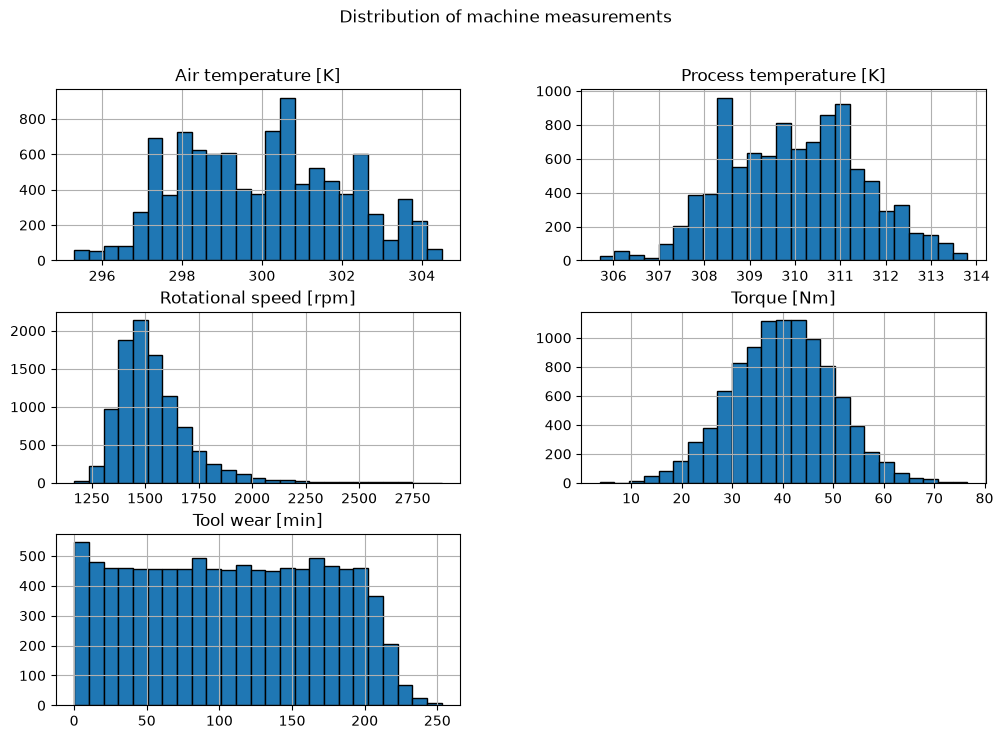

In [15]:
numerical_features = [
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]"
]

df[numerical_features].hist(figsize=(12, 8), bins=25, edgecolor="black")
plt.suptitle("Distribution of machine measurements")
plt.show()

## 8. Compare measurements by failure status

Boxplots help compare the median and spread of each measurement for observations with and without a recorded failure. The plot alone does not prove that a feature causes failure.

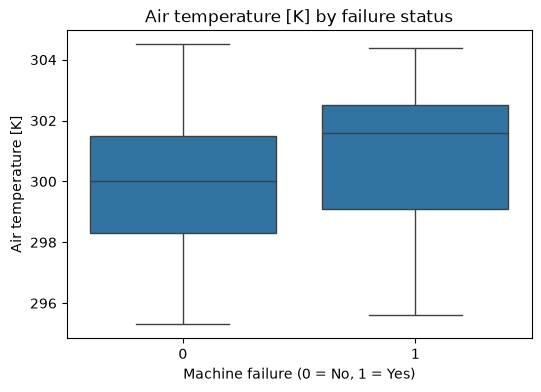

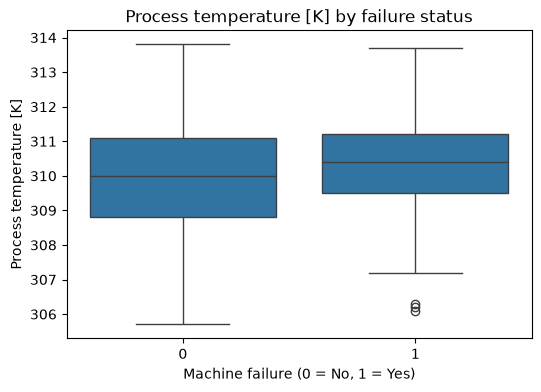

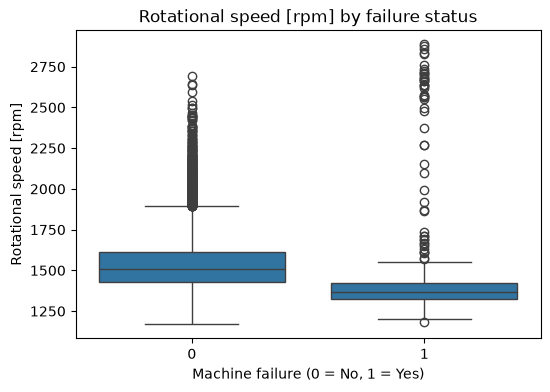

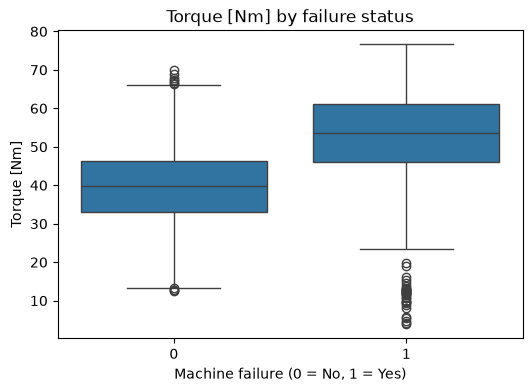

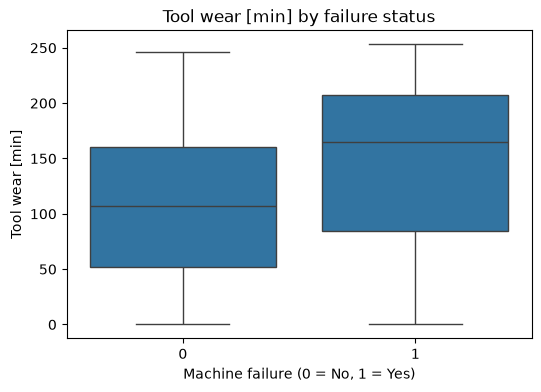

In [31]:
for column in numerical_features:
    plt.figure(figsize=(6, 4))
    sns.boxplot(data=df, x="Machine failure", y=column)
    plt.title(column + " by failure status")
    plt.xlabel("Machine failure (0 = No, 1 = Yes)")
    plt.show()

## 9. Numerical summary by target class

In [17]:

df.groupby("Machine failure")[numerical_features].agg(["mean", "median", "min", "max"]).round(2)


Air temperature [K]                       \
                               mean median    min    max   
Machine failure                                            
0                            299.97  300.0  295.3  304.5   
1                            300.89  301.6  295.6  304.4   

                Process temperature [K]                       \
                                   mean median    min    max   
Machine failure                                                
0                                310.00  310.0  305.7  313.8   
1                                310.29  310.4  306.1  313.7   

                Rotational speed [rpm]                     Torque [Nm]         \
                                  mean  median   min   max        mean median   
Machine failure                                                                 
0                              1540.26  1507.0  1168  2695       39.63   39.9   
1                              1496.49  1365.0  1181  2886       50.17   53.7   

                            Tool wear [min]                  
                  min   max            mean median min  max  
Machine failure                                              
0                12.6  70.0          106.69  107.0   0  246  
1                 3.8  76.6          143.78  165.0   0  253

## 10. Failure rate by product type

`Type` is a categorical feature with product categories. This table and chart compare the observed failure rate across the categories.

,Total_records,Failure_count,Failure_rate,Failure_rate_percent
Type,,,,
H,1003,21,0.020937,2.09
L,6000,235,0.039167,3.92
M,2997,83,0.027694,2.77


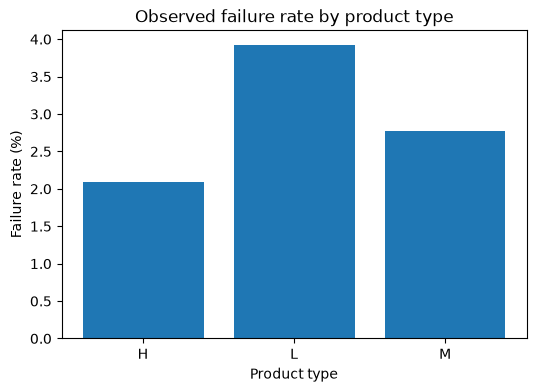

In [20]:
type_summary = df.groupby("Type")["Machine failure"].agg(
    Total_records="count",
    Failure_count="sum",
    Failure_rate="mean"
)
type_summary["Failure_rate_percent"] = (type_summary["Failure_rate"] * 100).round(2)
display(type_summary)

plt.figure(figsize=(6, 4))
plt.bar(type_summary.index, type_summary["Failure_rate_percent"])
plt.title("Observed failure rate by product type")
plt.xlabel("Product type")
plt.ylabel("Failure rate (%)")
plt.show()

## 11. Failure subtype counts (for understanding the dataset only)

The dataset also has columns for specific failure types. These are useful to describe the dataset, but they will **not** be used as input features because they are directly related to the failure outcome and could cause target leakage.

TWF     46
HDF    115
PWF     95
OSF     98
RNF     19
dtype: int64


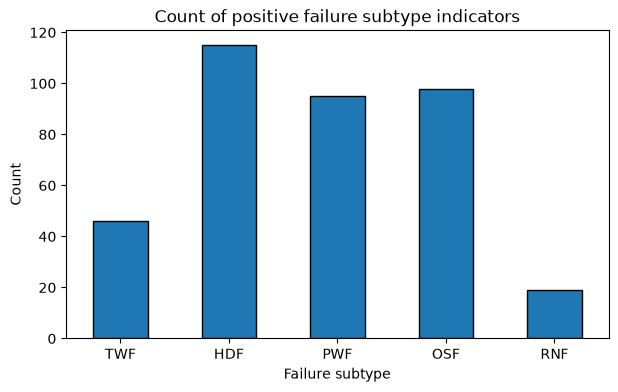

In [23]:
failure_subtypes = ["TWF", "HDF", "PWF", "OSF", "RNF"]
print(df[failure_subtypes].sum())

df[failure_subtypes].sum().plot(kind="bar", figsize=(7, 4), edgecolor="black")
plt.title("Count of positive failure subtype indicators")
plt.xlabel("Failure subtype")
plt.ylabel("Count")
plt.xticks(rotation=0)
plt.show()

## 12. Select input features and target

In [25]:
categorical_features = ["Type"]

numerical_features = [
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]"
]

feature_columns = categorical_features + numerical_features
X = df[feature_columns]
y = df["Machine failure"]

print("Input shape:", X.shape)
print("Target shape:", y.shape)
print("Input columns:", list(X.columns))

Input shape: (10000, 6)
Target shape: (10000,)
Input columns: ['Type', 'Air temperature [K]', 'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]']


## 13. Split the data into training and testing sets

In [26]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training input shape:", X_train.shape)
print("Testing input shape:", X_test.shape)


Training input shape: (8000, 6)
Testing input shape: (2000, 6)


## 14. Preprocessing pipeline

The data has one categorical input (`Type`) and five numerical inputs. The categorical value is filled with the most frequent value and one-hot encoded. Numerical values are filled with the median and standardised.

The preprocessing is placed inside each model pipeline. This means each model learns preprocessing values from the training data only.

In [32]:
numerical_preprocessing = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_preprocessing = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(transformers=[
    ("numerical", numerical_preprocessing, numerical_features),
    ("categorical", categorical_preprocessing, categorical_features)
])

# Fit only on training data and transform both sets
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

print("Processed training shape:", X_train_processed.shape)
print("Processed testing shape:", X_test_processed.shape)

Processed training shape: (8000, 8)
Processed testing shape: (2000, 8)


## 15. Select the models

1. Logistic Regression
2. Decision Tree
3. K-Nearest Neighbours (KNN)
4. Gaussian Naive Bayes
5. Random Forest (**ensemble: bagging**)
6. Gradient Boosting (**ensemble: boosting**)


In [33]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier

models = {
    "Logistic Regression": LogisticRegression(
        class_weight="balanced",
        max_iter=1000,
        random_state=42
    ),

    "Decision Tree": DecisionTreeClassifier(
        class_weight="balanced",
        random_state=42
    ),

    "KNN": KNeighborsClassifier(
        n_neighbors=5
    ),

    "Gaussian Naive Bayes": GaussianNB(),

    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        class_weight="balanced",
        random_state=42
    ),

    "Gradient Boosting": GradientBoostingClassifier(
        n_estimators=100,
        learning_rate=0.1,
        max_depth=3,
        random_state=42
    )
}

print("Number of selected models:", len(models))
print("Ensemble models: Random Forest and Gradient Boosting")

Number of selected models: 6
Ensemble models: Random Forest and Gradient Boosting


## 16. Train the models and calculate evaluation metrics

Each model is fitted using the training data and then tested on the same held-out test data. The metrics used here are accuracy, precision, recall, specificity and F1-score, along with the confusion matrix.

- **Accuracy:** percentage of all predictions that are correct.
- **Precision:** among the observations predicted as failures, how many were actual failures?
- **Recall:** among actual failures, how many did the model detect?
- **Specificity:** among normal observations, how many were correctly predicted as normal?
- **F1-score:** combines precision and recall.

Because failure observations are less common than normal observations, accuracy should not be used alone.

In [34]:
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report
)

trained_models = {}
results = []

for name, classifier in models.items():
    model_pipeline = Pipeline(steps=[
        ("preprocessing", preprocessor),
        ("classifier", classifier)
    ])

    model_pipeline.fit(X_train, y_train)
    y_pred = model_pipeline.predict(X_test)

    tn, fp, fn, tp = confusion_matrix(y_test, y_pred, labels=[0, 1]).ravel()
    specificity = tn / (tn + fp) if (tn + fp) > 0 else 0

    trained_models[name] = model_pipeline

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "Specificity": specificity,
        "F1-score": f1_score(y_test, y_pred, zero_division=0)
    })

    print(name, "completed")

results_df = pd.DataFrame(results).sort_values(
    by="F1-score", ascending=False
).reset_index(drop=True)

results_df.round(4)

Logistic Regression completed
Decision Tree completed
KNN completed
Gaussian Naive Bayes completed
Random Forest completed
Gradient Boosting completed


,Model,Accuracy,Precision,Recall,Specificity,F1-score
0,Gradient Boosting,0.9855,0.8824,0.6618,0.9969,0.7563
1,Random Forest,0.9780,0.6875,0.6471,0.9896,0.6667
2,Decision Tree,0.9790,0.7321,0.6029,0.9922,0.6613
3,KNN,0.9740,0.8333,0.2941,0.9979,0.4348
4,Logistic Regression,0.8245,0.1418,0.8235,0.8245,0.2419
5,Gaussian Naive Bayes,0.9580,0.2500,0.1176,0.9876,0.1600


## 17. Compare the models

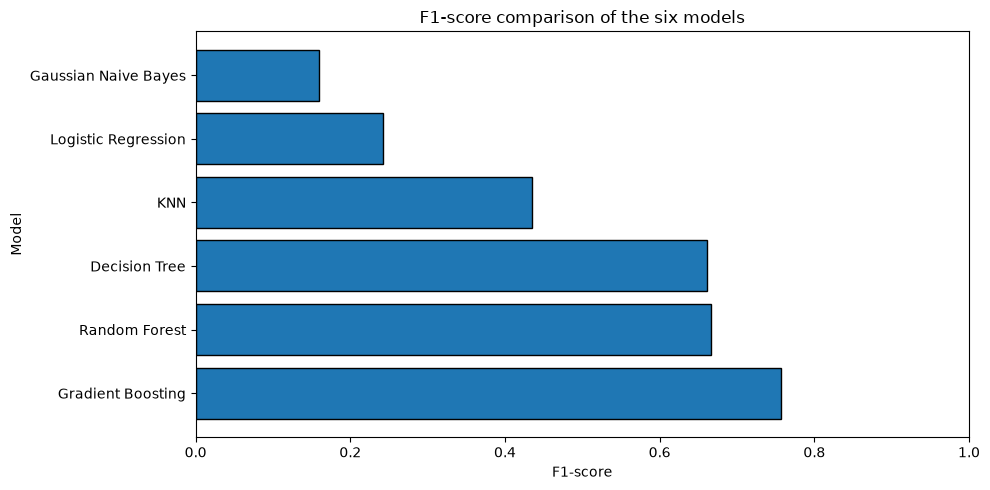

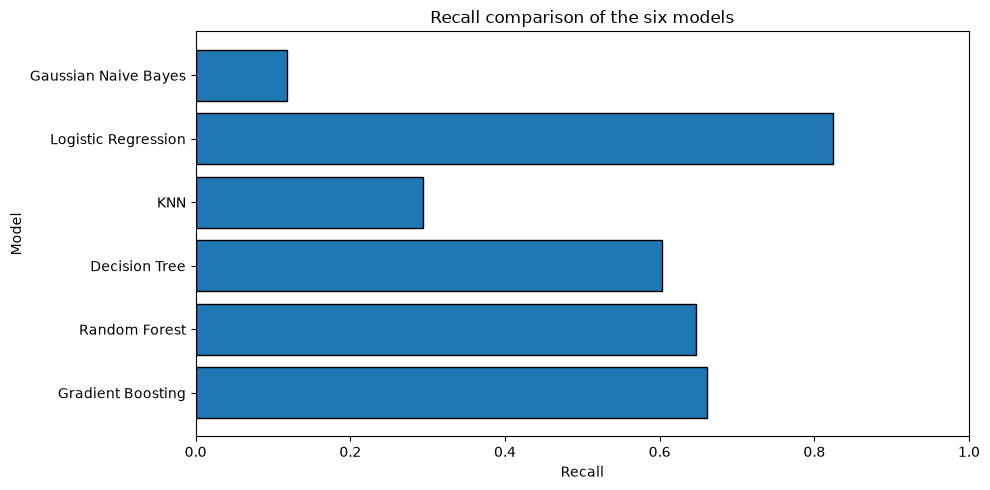

In [41]:
plt.figure(figsize=(10, 5))
plt.barh(results_df["Model"], results_df["F1-score"], edgecolor="black")
plt.title("F1-score comparison of the six models")
plt.xlabel("F1-score")
plt.ylabel("Model")
plt.xlim(0, 1)
plt.tight_layout()
plt.show()

plt.figure(figsize=(10, 5))
plt.barh(results_df["Model"], results_df["Recall"], edgecolor="black")
plt.title("Recall comparison of the six models")
plt.xlabel("Recall")
plt.ylabel("Model")
plt.xlim(0, 1)
plt.tight_layout()
plt.show()

## 18. Inspect confusion matrices

A confusion matrix shows the number of correct and incorrect predictions.

- **True Negative (TN):** normal observation predicted as normal.
- **False Positive (FP):** normal observation predicted as failure.
- **False Negative (FN):** failure observation predicted as normal.
- **True Positive (TP):** failure observation predicted as failure.

False negatives are important here because they are actual failures the model did not detect.

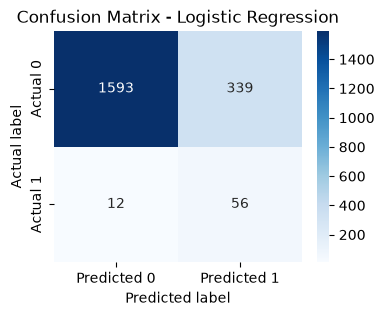

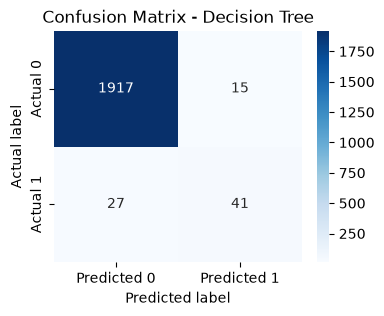

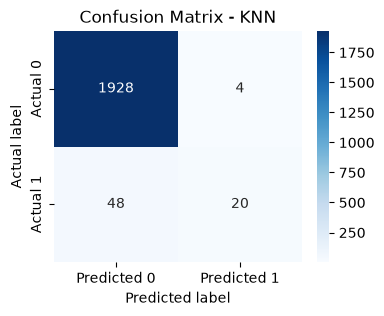

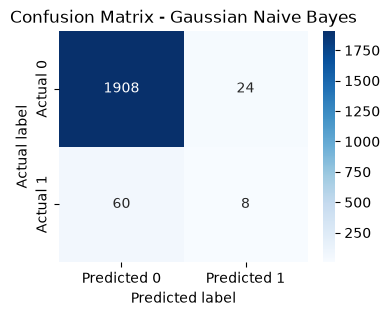

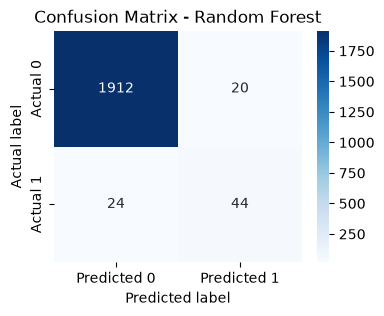

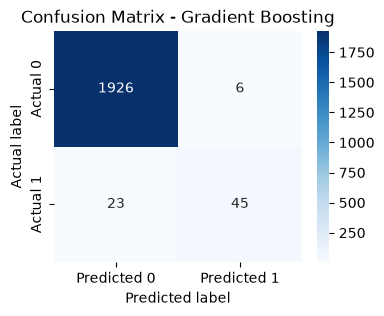

In [38]:
for name, model_pipeline in trained_models.items():
    y_pred = model_pipeline.predict(X_test)
    cm = confusion_matrix(y_test, y_pred)

    plt.figure(figsize=(4, 3))
    sns.heatmap(
        cm, annot=True, fmt="d", cmap="Blues",
        xticklabels=["Predicted 0", "Predicted 1"],
        yticklabels=["Actual 0", "Actual 1"]
    )
    plt.title("Confusion Matrix - " + name)
    plt.xlabel("Predicted label")
    plt.ylabel("Actual label")
    plt.show()

## 20. Select and inspect the best model from this comparison

For this preliminary comparison, the model with the highest F1-score is selected. Recall and the confusion matrix should also be checked because missing an actual failure can be costly in predictive maintenance.

In [37]:
best_model_name = results_df.loc[0, "Model"]
best_model = trained_models[best_model_name]
best_predictions = best_model.predict(X_test)

print("Best model by F1-score:", best_model_name)
print()
print(classification_report(
    y_test, best_predictions,
    target_names=["No failure (0)", "Failure (1)"],
    zero_division=0
))

print("Confusion matrix:")
display(pd.DataFrame(
    confusion_matrix(y_test, best_predictions),
    index=["Actual no failure", "Actual failure"],
    columns=["Predicted no failure", "Predicted failure"]
))

Best model by F1-score: Gradient Boosting

                precision    recall  f1-score   support

No failure (0)       0.99      1.00      0.99      1932
   Failure (1)       0.88      0.66      0.76        68

      accuracy                           0.99      2000
     macro avg       0.94      0.83      0.87      2000
  weighted avg       0.98      0.99      0.98      2000

Confusion matrix:


,Predicted no failure,Predicted failure
Actual no failure,1926,6
Actual failure,23,45
